<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Patient Dataset:
    Haemoglobin       RBC     Glucose  Cholesterol        BMI
0    15.164473  5.335413  106.848321   190.378778  29.539757
1    14.959707  4.867369   93.845498   192.814687  24.572999
2    11.133143  4.287996  103.309389   208.677775  24.581740
3    13.570139  4.862383   95.328621   190.821986  28.526523
4    13.680366  4.772226  107.782353   209.932051  28.551367

Covariance Matrix:
 [[ 1.00502513  0.88342354 -0.07479695 -0.03119675  0.11495164]
 [ 0.88342354  1.00502513 -0.03579608 -0.02443444  0.03804582]
 [-0.07479695 -0.03579608  1.00502513  0.00158737  0.03588106]
 [-0.03119675 -0.02443444  0.00158737  1.00502513  0.10239622]
 [ 0.11495164  0.03804582  0.03588106  0.10239622  1.00502513]]

Correlation Matrix:
 [[ 1.          0.87900642 -0.07442297 -0.03104076  0.11437688]
 [ 0.87900642  1.         -0.0356171  -0.02431226  0.03785559]
 [-0.07442297 -0.0356171   1.          0.00157943  0.03570166]
 [-0.03104076 -0.02431226  0.00157943  1.          0.10188424]
 [ 0.

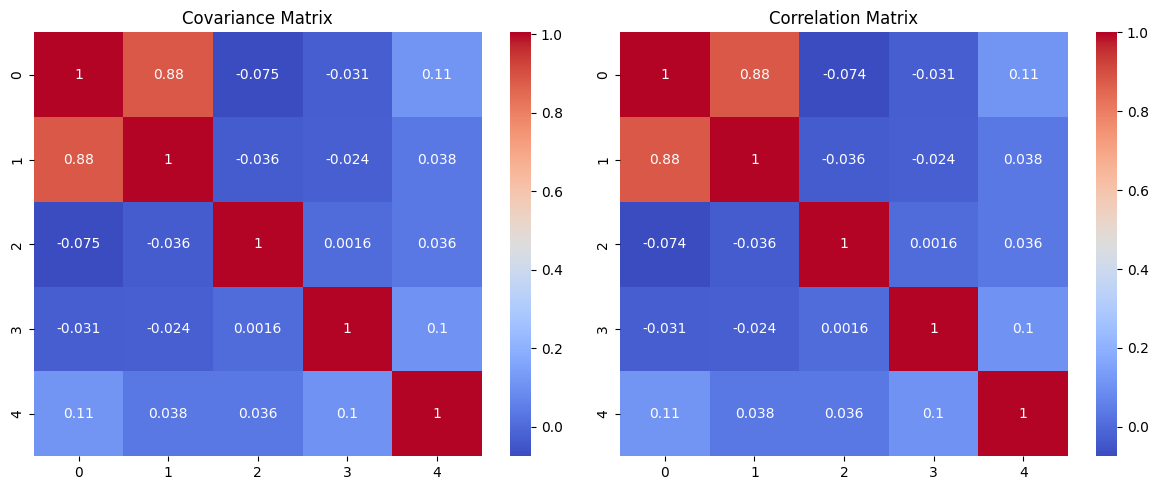


Eigenvalues:
 [1.90835266 1.11366852 1.00082517 0.8852077  0.11707158]

Eigenvectors:
 [[-0.70330161 -0.00648872 -0.02570392 -0.0411499   0.7092043 ]
 [-0.69658172 -0.04557128 -0.06171225 -0.13179204 -0.7010846 ]
 [ 0.08143739  0.2585426  -0.9237219  -0.26851632  0.0340663 ]
 [ 0.03056279  0.67016957  0.37644138 -0.63879657  0.01301882]
 [-0.11213664  0.69419711 -0.02367798  0.70765491 -0.06465008]]


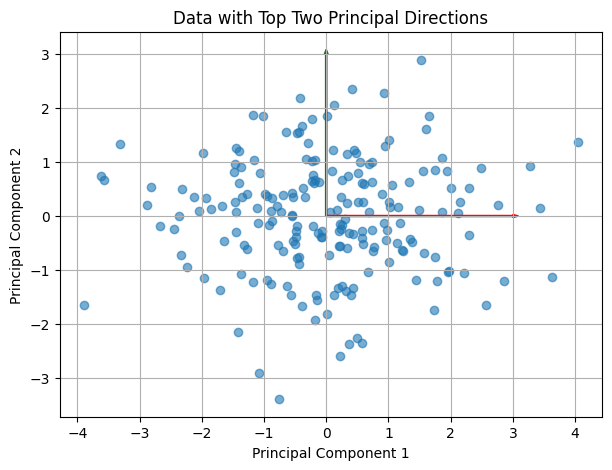


Percentage of Variance:
Component 1 : 37.98 %
Component 2 : 22.16 %
Component 3 : 19.92 %
Component 4 : 17.62 %
Component 5 : 2.33 %


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
np.random.seed(10)
n = 200
latent = np.random.normal(size=n)
data = pd.DataFrame({
    'Haemoglobin': 13.5 + 1.2*latent + np.random.normal(0,0.5,n),
    'RBC': 4.8 + 0.35*latent + np.random.normal(0,0.15,n),
    'Glucose': 100 + np.random.normal(0,12,n),
    'Cholesterol': 190 + np.random.normal(0,18,n),
    'BMI': 25 + np.random.normal(0,3,n)
})
print("Patient Dataset:\n", data.head())
scaler = StandardScaler()
X = scaler.fit_transform(data)
cov = np.cov(X, rowvar=False)
corr = np.corrcoef(X, rowvar=False)
print("\nCovariance Matrix:\n", cov)
print("\nCorrelation Matrix:\n", corr)
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.heatmap(cov, annot=True, cmap='coolwarm')
plt.title("Covariance Matrix")
plt.subplot(1,2,2)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()
values, vectors = np.linalg.eigh(cov)
idx = np.argsort(values)[::-1]
values = values[idx]
vectors = vectors[:,idx]
print("\nEigenvalues:\n", values)
print("\nEigenvectors:\n", vectors)
Z = X @ vectors[:, :2]
plt.figure(figsize=(7,5))
plt.scatter(Z[:,0], Z[:,1], alpha=0.6)
plt.arrow(0,0,3,0,color='red',width=0.02)
plt.arrow(0,0,0,3,color='green',width=0.02)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Data with Top Two Principal Directions")
plt.grid()
plt.show()
variance = values / np.sum(values) * 100
print("\nPercentage of Variance:")
for i, v in enumerate(variance):
    print("Component", i+1, ":", round(v,2), "%")